In [6]:
import sys
sys.path.append('../')

import numpy as np
import pickle

from weighted_conformal_clustering.utils import sample_gmm, soft_predict, SpectralGMM

from sklearn.metrics import adjusted_rand_score

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

### 50D Example with 5 Isotropic Components
(GMM50D5v1)

In [7]:
K = 5
d = 50

# generate means in 2D by equispaced points on a circle
means_2d = 4 * np.vstack([np.cos(np.pi * np.linspace(0, 2, K, endpoint=False)),
                      np.sin(np.pi * np.linspace(0, 2, K, endpoint=False))]).T

# embedding the 2D means into higher dimensions by padding with zeros
means = np.zeros((K, d))
means[:, :2] = means_2d

base_covariances = np.array([np.eye(d) for _ in range(K)])
weights = np.ones(K) / K

n = K*800

# check ARI
var_range = np.linspace(0.7, 2.5, 10)

for var in var_range:
    covariances = base_covariances * var
    X, y = sample_gmm(means, covariances, weights, n)

    sgmms = SpectralGMM(embedding='svd', n_components=K, random_state=1)
    sgmms.fit(X)
    y_sgmms = soft_predict(sgmms.probs, seed=1)
    ari = adjusted_rand_score(y, y_sgmms)
    print(f"Variance: {var:.2f}, ARI: {ari:.4f}")

Variance: 0.70, ARI: 0.9832
Variance: 0.90, ARI: 0.9513
Variance: 1.10, ARI: 0.9119
Variance: 1.30, ARI: 0.8588
Variance: 1.50, ARI: 0.8015
Variance: 1.70, ARI: 0.7359
Variance: 1.90, ARI: 0.6930
Variance: 2.10, ARI: 0.6538
Variance: 2.30, ARI: 0.6073
Variance: 2.50, ARI: 0.5728


### **Fixed Sample Size**

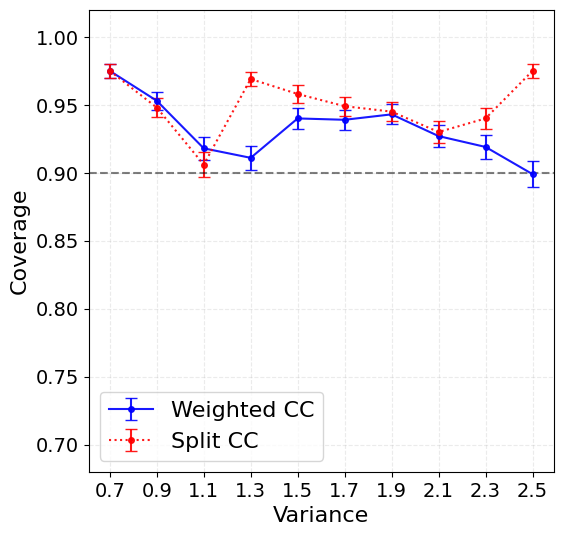

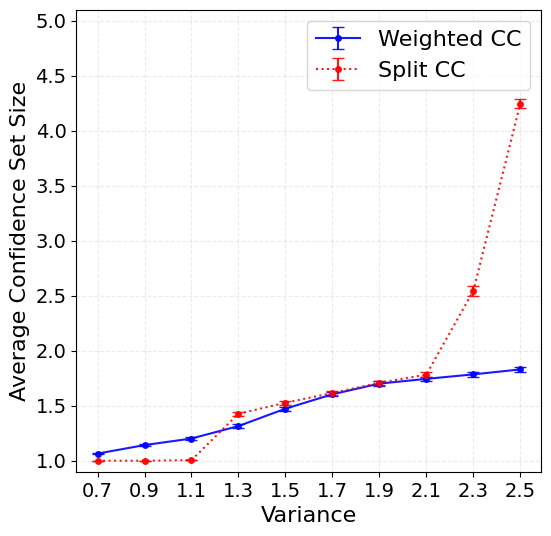

In [8]:
n = 3000
B = 1000
var_range = np.linspace(0.7, 2.5, 10)

with open(f'Results/GMM50D5v1kNNSpectral.pkl', 'rb') as f:
    results = pickle.load(f)
    
coverages = {'WeightedCC': [], 'SplitCC': []}
sizes = {'WeightedCC': [], 'SplitCC': []}

for method in ['WeightedCC', 'SplitCC']:
    cov, size = np.zeros((len(var_range), B)), np.zeros((len(var_range), B))
    for var_idx in range(len(var_range)):
        for b in range(B):
            res = results[var_idx*B + b]
            cov[var_idx, b], size[var_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    coverages[method] = (cov_mean, cov_se)
    sizes[method] = (size_mean, size_se)


# Errorbars with connected lines
plt.figure(figsize=(6,6))
plt.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.9, 5.1))
plt.show()

### **Asymptotic: Increasing Sample Size**

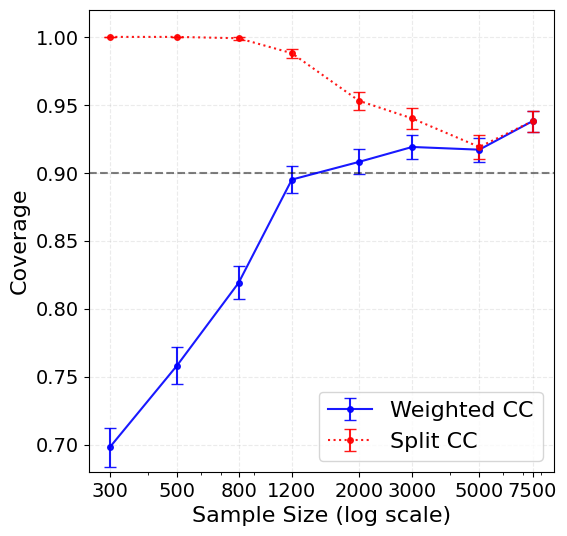

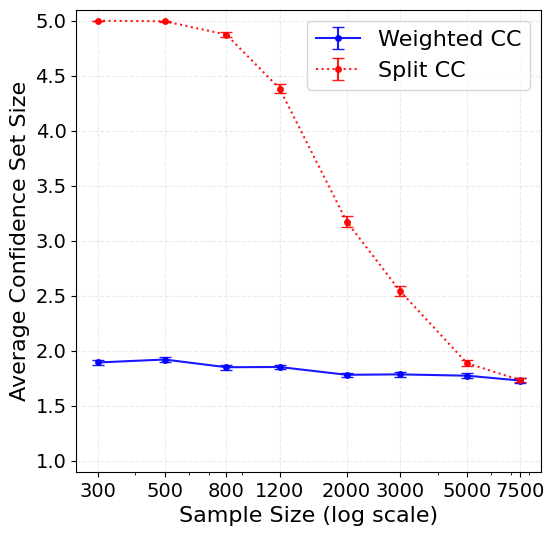

In [9]:
var = 2.3
B = 1000
n_range = [300, 500, 800, 1200, 2000, 3000, 5000, 7500]

with open(f'Results/GMM50D5v1kNNSpectral_asymp.pkl', 'rb') as f:
    results = pickle.load(f)

asymp_coverages = {'WeightedCC': [], 'SplitCC': []}
asymp_sizes = {'WeightedCC': [], 'SplitCC': []}

for method in ['WeightedCC', 'SplitCC']:
    cov, size = np.zeros((len(n_range), B)), np.zeros((len(n_range), B))
    for n_idx in range(len(n_range)):
        for b in range(B):
            res = results[n_idx*B + b]
            cov[n_idx, b], size[n_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    asymp_coverages[method] = (cov_mean, cov_se)
    asymp_sizes[method] = (size_mean, size_se)
    

# Errorbars with connected lines (x-axis = sample size in log scale)
plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.9, 5.1))
plt.show()

### Combined Figures

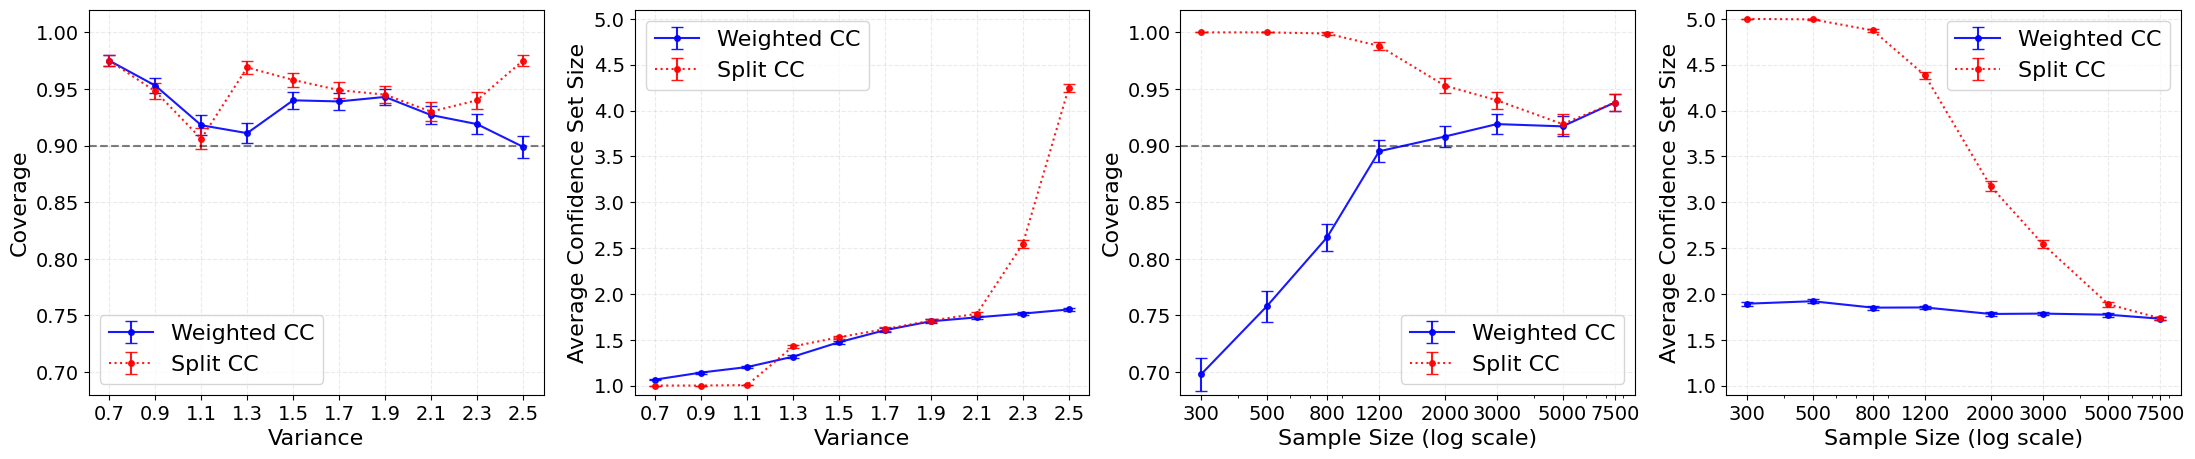

In [10]:
fig = plt.figure(figsize=(27, 5))
gs = GridSpec(nrows=1, ncols=4, figure=fig, wspace=0.2, hspace=0.2)

# Coverage (fixed sample size)
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax1.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax1.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Variance', fontsize=16)
ax1.set_xticks(var_range)
ax1.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax1.set_ylabel('Coverage', fontsize=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(fontsize=16)
ax1.grid(True, linestyle="--", alpha=0.25)
ax1.set_ylim((0.68, 1.02))

# Size (fixed sample size)
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax2.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax2.set_xlabel('Variance', fontsize=16)
ax2.set_xticks(var_range)
ax2.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax2.set_ylabel('Average Confidence Set Size', fontsize=16)
ax2.tick_params(axis='y', labelsize=14)
ax2.legend(fontsize=16)
ax2.grid(True, linestyle="--", alpha=0.25)
ax2.set_ylim((0.9, 5.1))

# Asymptotic coverage
ax3 = fig.add_subplot(gs[0, 2])
ax3.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax3.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax3.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax3.set_xlabel('Sample Size (log scale)', fontsize=16)
ax3.set_xscale('log')
ax3.set_xticks(n_range)
ax3.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax3.set_ylabel('Coverage', fontsize=16)
ax3.tick_params(axis='y', labelsize=14)
ax3.legend(fontsize=16)
ax3.grid(True, linestyle="--", alpha=0.25)
ax3.set_ylim((0.68, 1.02))

# Asymptotic size
ax4 = fig.add_subplot(gs[0, 3])
ax4.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax4.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax4.set_xlabel('Sample Size (log scale)', fontsize=16)
ax4.set_xscale('log')
ax4.set_xticks(n_range)
ax4.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax4.set_ylabel('Average Confidence Set Size', fontsize=16)
ax4.tick_params(axis='y', labelsize=14)
ax4.legend(fontsize=16)
ax4.grid(True, linestyle="--", alpha=0.25)
ax4.set_ylim((0.9, 5.1))

plt.savefig('Figures/GMM50D5v1kNNSpectral.pdf', bbox_inches='tight')
plt.show()